# Лабораторная работа № 1


**Вариант:** 18  
**Представление сплайна:** по моментам  
**Граничные условия:** III по листу распределения (условия IV в методических указаниях — «не узел»)

**Цель работы:** построить кубический интерполяционный сплайн класса $C^2$, проверить выполнение условий интерполяции и гладкости, сравнить значения сплайна с точной функцией в заданных точках и исследовать сходимость при сгущении сетки.




$$
f(x)=x^2-\frac12e^{-x}, \qquad x\in[0.1;\,0.6].
$$

 точки:

$$
x^*=0.37,\qquad x^{**}=0.12,\qquad x^{***}=0.58,\qquad x^{****}=0.33.
$$

На основной сетке используется 11 узлов, то есть $N=10$ интервалов и

$$
x_i=a+ih,\qquad h=\frac{b-a}{N}=0.05,\qquad i=0,1,\ldots,N.
$$


$$
S'''_0(x_1-0)=S'''_1(x_1+0),\qquad
S'''_{N-2}(x_{N-1}-0)=S'''_{N-1}(x_{N-1}+0).
$$

Это условие также называют условием **«не узел»**. Периодическое условие здесь неприменимо, поскольку $f(0.1)\ne f(0.6)$.


## 2. Формулы сплайна по моментам

Моментами называются значения второй производной сплайна в узлах:

$$
M_i=S''(x_i),\qquad i=0,1,\ldots,N.
$$

Обозначим

$$
h_i=x_i-x_{i-1},\qquad y_i=f(x_i).
$$

Для внутренних узлов моменты находятся из системы

$$
\frac{h_i}{6}M_{i-1}+\frac{h_i+h_{i+1}}{3}M_i+
\frac{h_{i+1}}{6}M_{i+1}
=
\frac{y_{i+1}-y_i}{h_{i+1}}-
\frac{y_i-y_{i-1}}{h_i},
\qquad i=1,\ldots,N-1.
$$

Так как на каждом интервале

$$
S'''_i(x)=\frac{M_{i+1}-M_i}{h_{i+1}},
$$

условия «не узел» дают два недостающих уравнения:

$$
\frac{M_1-M_0}{h_1}=\frac{M_2-M_1}{h_2},
\qquad
\frac{M_{N-1}-M_{N-2}}{h_{N-1}}=
\frac{M_N-M_{N-1}}{h_N}.
$$

После решения системы на отрезке $[x_i,x_{i+1}]$ сплайн вычисляется по формуле из методических указаний:

$$
S_i(x)=y_i+c_i(x-x_i)+\frac{M_i}{2}(x-x_i)^2+
\frac{M_{i+1}-M_i}{6h_{i+1}}(x-x_i)^3,
$$

где

$$
c_i=\frac{y_{i+1}-y_i}{h_{i+1}}-
\frac{h_{i+1}}{6}(2M_i+M_{i+1}).
$$

Для проверки гладкости используются производные

$$
S_i'(x)=c_i+M_i(x-x_i)+\frac{M_{i+1}-M_i}{2h_{i+1}}(x-x_i)^2,
$$

$$
S_i''(x)=M_i+\frac{M_{i+1}-M_i}{h_{i+1}}(x-x_i).
$$


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

np.set_printoptions(precision=10, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")


def md_table(headers, rows):
    # Вывод небольшой таблицы без дополнительных библиотек.
    head = "| " + " | ".join(headers) + " |"
    rule = "|" + "|".join(["---"] * len(headers)) + "|"
    body = ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join([head, rule, *body])))


In [ ]:
def f(x):
  
    x = np.asarray(x, dtype=float)
    return x**2 - 0.5 * np.exp(-x)


def build_moment_spline(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x) - 1
    if n < 3:
        raise ValueError("Для условий «не узел» нужно не менее трёх интервалов")

    h = np.diff(x)
    A = np.zeros((n + 1, n + 1))
    rhs = np.zeros(n + 1)

    # (M1-M0)/h1 = (M2-M1)/h2
    A[0, 0] = -1 / h[0]
    A[0, 1] = 1 / h[0] + 1 / h[1]
    A[0, 2] = -1 / h[1]

    # Уравнения непрерывности первой производной во внутренних узлах
    for i in range(1, n):
        A[i, i - 1] = h[i - 1] / 6
        A[i, i] = (h[i - 1] + h[i]) / 3
        A[i, i + 1] = h[i] / 6
        rhs[i] = ((y[i + 1] - y[i]) / h[i]
                  - (y[i] - y[i - 1]) / h[i - 1])

    # (M_{N-1}-M_{N-2})/h_{N-1} = (MN-M_{N-1})/hN
    A[n, n - 2] = -1 / h[-2]
    A[n, n - 1] = 1 / h[-2] + 1 / h[-1]
    A[n, n] = -1 / h[-1]

    M = np.linalg.solve(A, rhs)
    return M


def interval_coefficients(x, y, M):
    # Коэффициенты S_i=y_i+c_i*t+(M_i/2)*t^2+d_i*t^3.
    h = np.diff(x)
    c = np.diff(y) / h - h * (2 * M[:-1] + M[1:]) / 6
    d = (M[1:] - M[:-1]) / (6 * h)
    return c, d


def spline_value(x, y, M, z):
    # Значения сплайна; поддерживает число или массив точек.
    z = np.asarray(z, dtype=float)
    i = np.searchsorted(x, z, side="right") - 1
    i = np.clip(i, 0, len(x) - 2)
    h = x[i + 1] - x[i]
    t = z - x[i]
    c = ((y[i + 1] - y[i]) / h
         - h * (2 * M[i] + M[i + 1]) / 6)
    return (y[i] + c * t + M[i] * t**2 / 2
            + (M[i + 1] - M[i]) * t**3 / (6 * h))


def local_values(x, y, M, i, z):
    # S, S' и S'' на i-м интервале в точке z.
    h = x[i + 1] - x[i]
    t = z - x[i]
    c = ((y[i + 1] - y[i]) / h
         - h * (2 * M[i] + M[i + 1]) / 6)
    delta_M = M[i + 1] - M[i]
    S = y[i] + c * t + M[i] * t**2 / 2 + delta_M * t**3 / (6 * h)
    S1 = c + M[i] * t + delta_M * t**2 / (2 * h)
    S2 = M[i] + delta_M * t / h
    return S, S1, S2


## 3. Построение сплайна на основной сетке

Сначала построим таблицу из 11 значений функции, решим систему для моментов и получим коэффициенты каждого кубического участка.


In [3]:
a, b = 0.1, 0.6
N = 10
x = np.linspace(a, b, N + 1)
y = f(x)
M = build_moment_spline(x, y)
c, d = interval_coefficients(x, y, M)

md_table(
    ["$i$", "$x_i$", "$y_i=f(x_i)$", "$M_i=S''(x_i)$"],
    [[i, f"{x[i]:.2f}", f"{y[i]:.10f}", f"{M[i]:.10f}"]
     for i in range(N + 1)]
)

md_table(
    ["$i$", "Интервал", "$c_i$", "$M_i/2$", "$d_i$"],
    [[i, f"[{x[i]:.2f}; {x[i+1]:.2f}]", f"{c[i]:.10f}",
      f"{M[i]/2:.10f}", f"{d[i]:.10f}"]
     for i in range(N)]
)


| $i$ | $x_i$ | $y_i=f(x_i)$ | $M_i=S''(x_i)$ |
|---|---|---|---|
| 0 | 0.10 | -0.4424187090 | 1.5483447355 |
| 1 | 0.15 | -0.4078539882 | 1.5695563472 |
| 2 | 0.20 | -0.3693653765 | 1.5907679590 |
| 3 | 0.25 | -0.3269003915 | 1.6106678084 |
| 4 | 0.30 | -0.2804091103 | 1.6296716674 |
| 5 | 0.35 | -0.2298440449 | 1.6477278102 |
| 6 | 0.40 | -0.1751600230 | 1.6649123561 |
| 7 | 0.45 | -0.1163140758 | 1.6812436424 |
| 8 | 0.50 | -0.0532653299 | 1.6968300686 |
| 9 | 0.55 | 0.0140250948 | 1.7114649909 |
| 10 | 0.60 | 0.0855941820 | 1.7260999131 |

| $i$ | Интервал | $c_i$ | $M_i/2$ | $d_i$ |
|---|---|---|---|---|
| 0 | [0.10; 0.15] | 0.6524090343 | 0.7741723678 | 0.0707053724 |
| 1 | [0.15; 0.20] | 0.7303565614 | 0.7847781736 | 0.0707053724 |
| 2 | [0.20; 0.25] | 0.8093646690 | 0.7953839795 | 0.0663328313 |
| 3 | [0.25; 0.30] | 0.8894005632 | 0.8053339042 | 0.0633461967 |
| 4 | [0.30; 0.35] | 0.9704090501 | 0.8148358337 | 0.0601871426 |
| 5 | [0.35; 0.40] | 1.0523440370 | 0.8238639051 | 0.0572818198 |
| 6 | [0.40; 0.45] | 1.1351600412 | 0.8324561780 | 0.0544376211 |
| 7 | [0.45; 0.50] | 1.2188139411 | 0.8406218212 | 0.0519547539 |
| 8 | [0.50; 0.55] | 1.3032657839 | 0.8484150343 | 0.0487830743 |
| 9 | [0.55; 0.60] | 1.3884731604 | 0.8557324954 | 0.0487830743 |

## 4. Сравнение с точными значениями

Абсолютная погрешность в контрольной точке вычисляется по формуле

$$
\Delta(x)=|S(x)-f(x)|.
$$


In [4]:
control_labels = ["$x^*$", "$x^{**}$", "$x^{***}$", "$x^{****}$"]
control_x = np.array([0.37, 0.12, 0.58, 0.33])
exact = f(control_x)
approx = spline_value(x, y, M, control_x)
errors = np.abs(approx - exact)

md_table(
    ["Точка", "$x$", "$f(x)$", "$S(x)$", "$|S(x)-f(x)|$"],
    [[label, f"{z:.2f}", f"{true:.12f}", f"{spl:.12f}", f"{err:.3e}"]
     for label, z, true, spl, err
     in zip(control_labels, control_x, exact, approx, errors)]
)


| Точка | $x$ | $f(x)$ | $S(x)$ | $|S(x)-f(x)|$ |
|---|---|---|---|---|
| $x^*$ | 0.37 | -0.208467165319 | -0.208467160302 | 5.016e-09 |
| $x^{**}$ | 0.12 | -0.429060218359 | -0.429060293742 | 7.538e-08 |
| $x^{***}$ | 0.58 | 0.056450816717 | 0.056450766011 | 5.071e-08 |
| $x^{****}$ | 0.33 | -0.250561866716 | -0.250561861535 | 5.181e-09 |

## 5. Проверка условий интерполяции и гладкости

В узлах должны выполняться условия

$$
S(x_i)=y_i,qquad
S'(x_i-0)=S'(x_i+0),qquad
S''(x_i-0)=S''(x_i+0).
$$

Также проверим два граничных условия «не узел» по значениям третьей производной.


In [5]:
node_residual = np.max(np.abs(spline_value(x, y, M, x) - y))

jumps = []
for i in range(1, N):
    left = local_values(x, y, M, i - 1, x[i])
    right = local_values(x, y, M, i, x[i])
    jumps.append(np.abs(np.asarray(left) - np.asarray(right)))
jumps = np.asarray(jumps)

third = np.diff(M) / np.diff(x)
left_not_a_knot = abs(third[0] - third[1])
right_not_a_knot = abs(third[-2] - third[-1])

md_table(
    ["Проверяемая величина", "Максимальное отклонение"],
    [
        ["Интерполяция $S(x_i)=y_i$", f"{node_residual:.3e}"],
        ["Непрерывность $S$", f"{np.max(jumps[:, 0]):.3e}"],
        ["Непрерывность $S'$", f"{np.max(jumps[:, 1]):.3e}"],
        ["Непрерывность $S''$", f"{np.max(jumps[:, 2]):.3e}"],
        ["Левое условие «не узел»", f"{left_not_a_knot:.3e}"],
        ["Правое условие «не узел»", f"{right_not_a_knot:.3e}"],
    ]
)


| Проверяемая величина | Максимальное отклонение |
|---|---|
| Интерполяция $S(x_i)=y_i$ | 1.388e-17 |
| Непрерывность $S$ | 2.776e-17 |
| Непрерывность $S'$ | 2.220e-16 |
| Непрерывность $S''$ | 0.000e+00 |
| Левое условие «не узел» | 4.718e-15 |
| Правое условие «не узел» | 5.107e-15 |

## 6. Исследование сходимости

Повторим эксперимент на сетках с $N=5,10,20,40,80$ интервалами. Максимальную погрешность оценим на плотной контрольной сетке:

$$
E_N=\max_{x\in[a,b]}|S_N(x)-f(x)|.
$$

Наблюдаемый порядок сходимости при удвоении числа интервалов:

$$
p_N=\log_2\frac{E_N}{E_{2N}}.
$$


In [6]:
dense_x = np.linspace(a, b, 20001)
grid_sizes = [5, 10, 20, 40, 80]
convergence = []
previous_error = None

for n in grid_sizes:
    xn = np.linspace(a, b, n + 1)
    yn = f(xn)
    Mn = build_moment_spline(xn, yn)
    dense_error = np.max(np.abs(spline_value(xn, yn, Mn, dense_x) - f(dense_x)))
    point_error = np.max(np.abs(spline_value(xn, yn, Mn, control_x) - exact))
    order = "—" if previous_error is None else f"{np.log2(previous_error / dense_error):.4f}"
    convergence.append([n, f"{(b-a)/n:.6f}", f"{dense_error:.3e}",
                        f"{point_error:.3e}", order])
    previous_error = dense_error

md_table(
    ["$N$", "$h$", "$E_N$ на $[a,b]$", "Макс. ошибка в 4 точках", "$p_N$"],
    convergence
)


| $N$ | $h$ | $E_N$ на $[a,b]$ | Макс. ошибка в 4 точках | $p_N$ |
|---|---|---|---|---|
| 5 | 0.100000 | 1.175e-06 | 9.768e-07 | — |
| 10 | 0.050000 | 7.590e-08 | 7.538e-08 | 3.9530 |
| 20 | 0.025000 | 4.867e-09 | 1.864e-09 | 3.9629 |
| 40 | 0.012500 | 3.081e-10 | 9.668e-11 | 3.9814 |
| 80 | 0.006250 | 1.938e-11 | 1.042e-12 | 3.9907 |

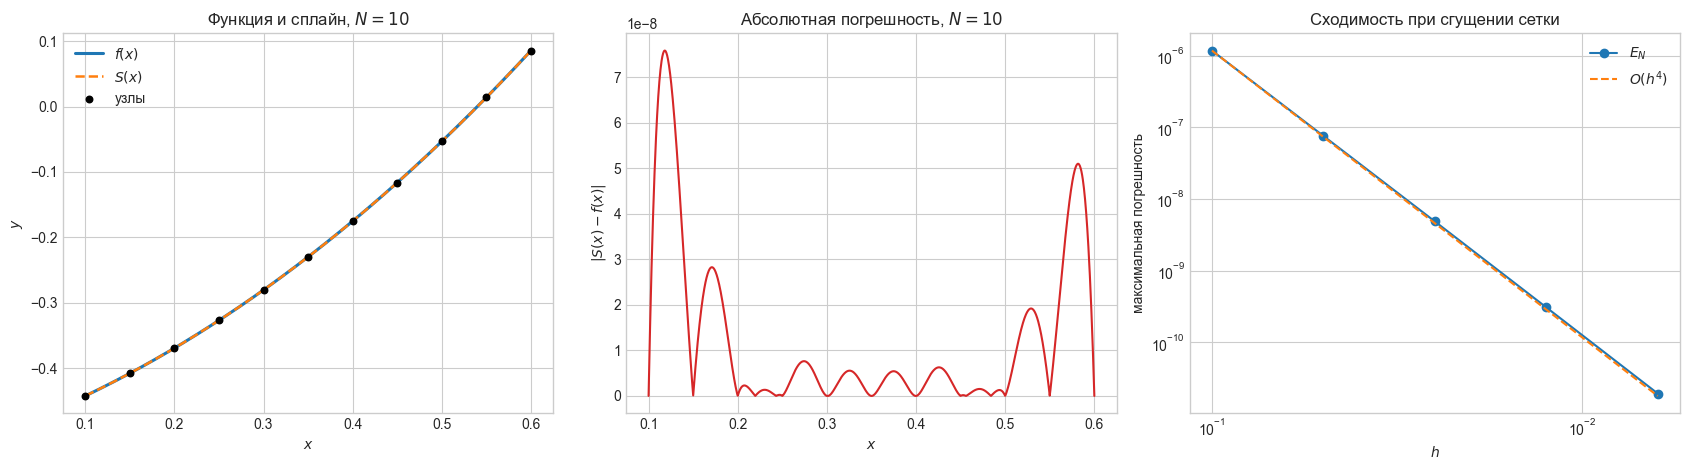

In [7]:
# Графики основной сетки и сходимости
plot_x = np.linspace(a, b, 1200)
plot_s = spline_value(x, y, M, plot_x)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].plot(plot_x, f(plot_x), label="$f(x)$", linewidth=2.2)
axes[0].plot(plot_x, plot_s, "--", label="$S(x)$", linewidth=1.8)
axes[0].scatter(x, y, color="black", s=22, zorder=3, label="узлы")
axes[0].set_title("Функция и сплайн, $N=10$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].legend()

axes[1].plot(plot_x, np.abs(plot_s - f(plot_x)), color="tab:red")
axes[1].set_title("Абсолютная погрешность, $N=10$")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$|S(x)-f(x)|$")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

hs = np.array([(b - a) / n for n in grid_sizes])
Es = np.array([float(row[2]) for row in convergence])
axes[2].loglog(hs, Es, "o-", label="$E_N$")
axes[2].loglog(hs, Es[0] * (hs / hs[0])**4, "--", label="$O(h^4)$")
axes[2].invert_xaxis()
axes[2].set_title("Сходимость при сгущении сетки")
axes[2].set_xlabel("$h$")
axes[2].set_ylabel("максимальная погрешность")
axes[2].legend()

plt.tight_layout()
plt.show()
